In [1]:
import numpy as np
import pandas as pd
import sklearn
import scipy
import lightgbm

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("LightGBM:", lightgbm.__version__)
print("Environment ready!")

NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
SciPy: 1.16.3
LightGBM: 4.6.0
Environment ready!


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os

drive_folder = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_folder):
    for file in files:
        if file.lower() == "student folder.zip":
            print("FOUND:", os.path.join(root, file))

In [7]:
import os

path = "/content/drive/MyDrive"

print(os.listdir(path))

['Colab Notebooks', 'PES2UG24CS156_Dhanyashree K M_CN Lab1 (1).pdf', 'PES2UG24CS156_Dhanyashree K M_CN Lab1.pdf', 'PES2UG24CS156_C.gdoc', 'PES2UG24CS156_C.pdf', 'PES2UG24CS156_Dhanyashree K M_CN Lab2.pdf', 'PES2UG24CS156_Dhanyashree K M_Lab 3.gdoc', 'PES2UG24CS156_Dhanyashree K M_Lab 3.pdf', 'PES2UG24CS156_OS(Orange level).gdoc', 'PES2UG24CS156_OS(Orange level).pdf', 'PES2UG24CS156_CN(Lab-4).pdf', 'Dhanyashree K M_PES2UG24CS156.gdoc', 'Dhanyashree K M_PES2UG24CS156.pdf', 'PES2UG24CS156_CN(LAB-5).pdf', 'PES2UG24CS156_OS(Unit-4)  (1).pdf', 'PES2UG24CS156_OS(Unit-4) .pdf', 'PES2UG24CS156_Dhanyashree K M_SDN.pdf', 'ML Lab 1.ipynb', 'Machine Learning Lab1.pdf', 'PES2UG24CS156_ML_Lab_2.ipynb', 'PES2UG24AM030_DBMS_LAB-2.pdf', 'PES2UG24CS156_DDL_Schema_Lab3.pdf', 'PES2UG24CS156_SE_Lab1.pdf', 'Use_Case_Diagram.pdf', 'EC_SRD_Worksheet1b_PES2UG24CS156.ipynb', 'EC_SRD_Worksheet1a_PES2UG24CS156.ipynb', 'PES2UG24CS156_ML_LAB4.ipynb', 'SE_PES2UG24CS156_JIRA_LAB.pdf', 'Dhanyashree K M_PES2UG24CS156_La

In [8]:
from google.colab import files

uploaded = files.upload()

Saving Student folder.zip to Student folder (1).zip


In [9]:
import zipfile
import os

zip_path = "/content/Student folder (1).zip"
extract_path = "/content/pathsnap_data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print(os.listdir(extract_path))

Extraction completed!
['Student folder']


In [10]:
import os

dataset = "/content/pathsnap_data/Student folder"

print("Main folders:", os.listdir(dataset))
print("Training trips:", len(os.listdir(os.path.join(dataset, "train"))))
print("Student test trips:", len(os.listdir(os.path.join(dataset, "student_test"))))

Main folders: ['student_test', 'train']
Training trips: 80
Student test trips: 10


Load and Explore the GPS and Road Network Dataset

In [11]:
import numpy as np
import os

trip_path = "/content/pathsnap_data/Student folder/train/00000001"

track = np.loadtxt(os.path.join(trip_path, "00000001.track"))
nodes = np.loadtxt(os.path.join(trip_path, "00000001.nodes"))
arcs = np.loadtxt(os.path.join(trip_path, "00000001.arcs"), dtype=int)
route = np.loadtxt(os.path.join(trip_path, "00000001.route"), dtype=int)

print("GPS observations:", track.shape)
print("Road nodes:", nodes.shape)
print("Road connections:", arcs.shape)
print("Reference route:", route.shape)

print("\nFirst 3 GPS observations:\n", track[:3])
print("\nFirst 3 road connections:\n", arcs[:3])
print("\nFirst 10 reference route IDs:\n", route[:10])

GPS observations: (1315, 3)
Road nodes: (88809, 2)
Road connections: (165790, 2)
Reference route: (525,)

First 3 GPS observations:
 [[ 8.595203 49.844053  1.      ]
 [ 8.595294 49.844441  2.      ]
 [ 8.595352 49.844883  3.      ]]

First 3 road connections:
 [[  0 281]
 [  0   1]
 [  0   5]]

First 10 reference route IDs:
 [  2641  64973 133948 133949 139208 133950   8970 133951  64139 139211]


Validate Reference Route Arc IDs

In [12]:
print("Total road connections:", len(arcs))
print("Minimum route arc ID:", route.min())
print("Maximum route arc ID:", route.max())

print("All route IDs valid:",
      np.all((route >= 0) & (route < len(arcs))))

print("Unique route arcs:", len(np.unique(route)))


Total road connections: 165790
Minimum route arc ID: 213
Maximum route arc ID: 165275
All route IDs valid: True
Unique route arcs: 525


Analyse GPS Timestamp Intervals

In [13]:
time_gaps = np.diff(track[:, 2])

unique_gaps, counts = np.unique(time_gaps, return_counts=True)

print("GPS time gaps (seconds):")
for gap, count in zip(unique_gaps, counts):
    print(f"{gap} second(s): {count} occurrences")

print("\nMinimum time gap:", time_gaps.min())
print("Maximum time gap:", time_gaps.max())
print("Average time gap:", time_gaps.mean())


GPS time gaps (seconds):
1.0 second(s): 1289 occurrences
2.0 second(s): 21 occurrences
3.0 second(s): 2 occurrences
4.0 second(s): 1 occurrences
16.0 second(s): 1 occurrences

Minimum time gap: 1.0
Maximum time gap: 16.0
Average time gap: 1.0327245053272451


Check GPS Coordinate Range

In [14]:
print("Longitude range:", track[:, 0].min(), "to", track[:, 0].max())
print("Latitude range:", track[:, 1].min(), "to", track[:, 1].max())

print("\nFirst GPS point:", track[0, :2])
print("Last GPS point:", track[-1, :2])

Longitude range: 8.570524 to 8.64786
Latitude range: 49.844053 to 50.211882

First GPS point: [ 8.595203 49.844053]
Last GPS point: [ 8.570524 50.194015]


Check Road Network Node and Arc Validity

In [15]:
print("Total nodes:", len(nodes))
print("Total arcs:", len(arcs))

print("Minimum node ID in arcs:", arcs.min())
print("Maximum node ID in arcs:", arcs.max())

print("All arc node IDs valid:",
      np.all((arcs >= 0) & (arcs < len(nodes))))

Total nodes: 88809
Total arcs: 165790
Minimum node ID in arcs: 0
Maximum node ID in arcs: 88808
All arc node IDs valid: True


Check for Duplicate Road Connections

In [16]:
unique_arcs = np.unique(arcs, axis=0)

print("Total arcs:", len(arcs))
print("Unique arcs:", len(unique_arcs))
print("Duplicate arcs:", len(arcs) - len(unique_arcs))


Total arcs: 165790
Unique arcs: 165498
Duplicate arcs: 292


Check GPS Data for Missing or Invalid Values

In [17]:
print("Missing values:", np.isnan(track).sum())
print("Infinite values:", np.isinf(track).sum())

print("Valid longitude range:",
      np.all((track[:, 0] >= -180) & (track[:, 0] <= 180)))

print("Valid latitude range:",
      np.all((track[:, 1] >= -90) & (track[:, 1] <= 90)))

Missing values: 0
Infinite values: 0
Valid longitude range: True
Valid latitude range: True


Check the Reference Route Length

In [18]:
print("GPS observations:", len(track))
print("Reference route arcs:", len(route))

print("GPS-to-route count ratio:",
      round(len(track) / len(route), 2))

GPS observations: 1315
Reference route arcs: 525
GPS-to-route count ratio: 2.5


Visualise the GPS Trajectory

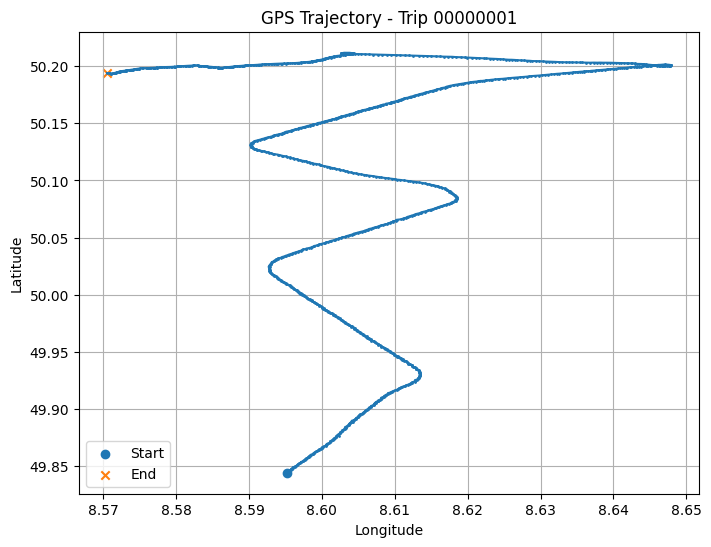

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.plot(track[:, 0], track[:, 1], marker='.', markersize=2)

plt.scatter(track[0, 0], track[0, 1], label="Start", marker="o")
plt.scatter(track[-1, 0], track[-1, 1], label="End", marker="x")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("GPS Trajectory - Trip 00000001")
plt.legend()
plt.grid(True)
plt.show()

Analyse Road Network Geographical Coverage

In [20]:
print("Road network longitude range:",
      nodes[:, 0].min(), "to", nodes[:, 0].max())

print("Road network latitude range:",
      nodes[:, 1].min(), "to", nodes[:, 1].max())

print("\nGPS longitude range:",
      track[:, 0].min(), "to", track[:, 0].max())

print("GPS latitude range:",
      track[:, 1].min(), "to", track[:, 1].max())

Road network longitude range: 8.560594 to 8.65786
Road network latitude range: 49.833564 to 50.221877

GPS longitude range: 8.570524 to 8.64786
GPS latitude range: 49.844053 to 50.211882
